# Sprint 1 — Data Preparation & Exploratory Data Analysis
**Millennium BCP × FEP — Predicting Daily Account Balances**

Goal of the case study: forecast the daily balance of every account for the next **30 days**, evaluated with **MAPE**.

Goal of this sprint: understand the time series, find what has to be corrected before modelling, and define how models
will be validated. The notebook is organised in four parts:

- **Part A — Getting to know the data:** structure, missing values, a calendar audit (which uncovered a change in how
  dates are recorded), descriptive statistics, the zero/near-zero problem for MAPE, and extreme values.
- **Part B — Temporal structure:** calendar effects, decomposition, stationarity, autocorrelation, volatility and
  structural changes.
- **Part C — Relationships between accounts:** cross-account correlation and segmentation.
- **Part D — Decisions:** data-preparation decisions, validation scheme and baseline MAPE for Sprint 2.

The notebook is self-contained: it only needs the CSV file given by the professor (set `DATA_PATH` below).

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import MSTL, STL
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

# ---- Parameters ---------------------------------------------------------------
DATA_PATH = "../data/raw/medium-dataset.csv"   # the only input of this notebook
HORIZON = 30                # forecast horizon (days)
NEAR_ZERO = 100.0           # |balance| below this (EUR) is considered "near zero" for MAPE purposes
RANDOM_STATE = 42
MAX_TEST_ACCOUNTS = 1000    # cap for per-account statistical tests (keeps runtime bounded on the large dataset)
MAX_CORR_ACCOUNTS = 300     # cap for the account x account correlation matrix
rng = np.random.default_rng(RANDOM_STATE)


def resolve_path(p):
    """Accept the path relative to the notebook folder or to the project root."""
    p = Path(p)
    for cand in (p, Path.cwd().parent / p, Path.cwd() / "data" / "raw" / p.name):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"Data file not found: {p}")


def sample_accounts(index, k):
    """Fixed random sample of at most k accounts (reproducible)."""
    if len(index) <= k:
        return index
    return pd.Index(np.sort(rng.choice(index.to_numpy(), size=k, replace=False)))


# ---- Saving analysis results ---------------------------------------------------
# Every table produced by the analysis is also written to CSV (data/sprint1/), so the results can be consulted
# without re-running the notebook. 00_index.csv lists every file with a description.
SAVE_RESULTS = True
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "data" / "sprint1"
saved_files = []


def save_result(obj, name, description, index=True):
    """Write a Series/DataFrame to RESULTS_DIR/<name>.csv and register it in the index."""
    if not SAVE_RESULTS:
        return
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    df.to_csv(RESULTS_DIR / f"{name}.csv", index=index)
    saved_files.append({"file": f"{name}.csv", "description": description,
                        "rows": df.shape[0], "columns": df.shape[1]})

# Part A — Getting to know the data
## 1. Loading and structure
The file is in *wide* format: one row per account (`ACCOUNT_ID`) and one column per calendar day.
We keep it as an accounts × days matrix — all operations below are vectorised over that matrix, so the same code
scales to the large dataset.

In [2]:
raw = pd.read_csv(resolve_path(DATA_PATH)).set_index("ACCOUNT_ID")
raw.columns = pd.to_datetime(raw.columns)
raw.columns.name = "date"
raw = raw.astype("float64")

dates = raw.columns
full_range = pd.date_range(dates.min(), dates.max(), freq="D")
values = raw.to_numpy()
observed = values[~np.isnan(values)]

not_cents = np.abs(np.round(observed * 100) - observed * 100) > 1e-6
structure = pd.Series({
    "accounts": raw.shape[0],
    "days": raw.shape[1],
    "first date": dates.min().date(),
    "last date": dates.max().date(),
    "calendar days missing from columns": len(full_range.difference(dates)),
    "duplicated account IDs": int(raw.index.duplicated().sum()),
    "duplicated dates": int(dates.duplicated().sum()),
    "observed values": len(observed),
    "values not in whole cents": int(not_cents.sum()),
})
save_result(structure.astype(str).rename("value"), "01_structure", "Dataset structure: size, date range, duplicates")
structure.to_frame("value")

,value
accounts,500
days,1095
first date,2020-01-02
last date,2022-12-31
calendar days missing from columns,0
duplicated account IDs,0
duplicated dates,0
observed values,541647
values not in whole cents,0


The panel is complete at the date level: every calendar day (including weekends and holidays) has a column, there
are no duplicated accounts or dates, and balances are recorded in euro cents.

## 2. Missing values
Missing values can mean very different things depending on *where* they are:
**leading** (the account did not exist yet), **trailing** (the account was closed) or **interior** (recording gaps).

,value
missing values,5853.00
% of all cells,1.07
accounts with any missing,25.00
accounts entirely missing,0.00
leading missing (account not opened yet),5853.00
trailing missing (account closed),0.00
interior missing (gaps),0.00


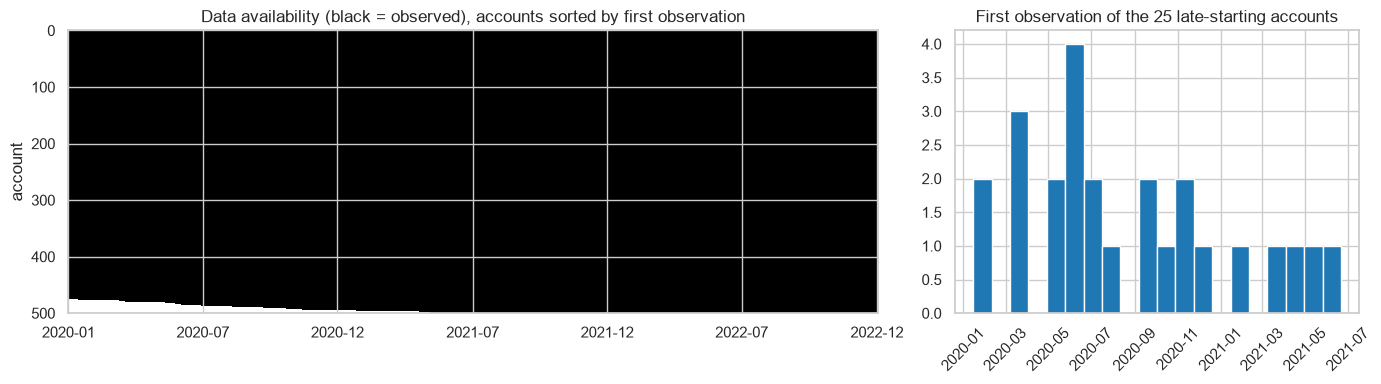

In [3]:
na = np.isnan(values)
n_leading = np.where(na.all(axis=1), na.shape[1], np.argmax(~na, axis=1))
n_trailing = np.where(na.all(axis=1), 0, np.argmax(~na[:, ::-1], axis=1))
n_interior = na.sum(axis=1) - n_leading - n_trailing

missing = pd.Series({
    "missing values": int(na.sum()),
    "% of all cells": round(100 * na.mean(), 2),
    "accounts with any missing": int(na.any(axis=1).sum()),
    "accounts entirely missing": int(na.all(axis=1).sum()),
    "leading missing (account not opened yet)": int(n_leading.sum()),
    "trailing missing (account closed)": int(n_trailing.sum()),
    "interior missing (gaps)": int(n_interior.sum()),
})
display(missing.to_frame("value"))

first_obs = pd.Series(dates[np.minimum(n_leading, len(dates) - 1)], index=raw.index, name="first_observation")
late = first_obs[first_obs > dates.min()]
save_result(missing.rename("value"), "02_missing_summary", "Missing values: totals by type (leading/trailing/interior)")
save_result(pd.DataFrame({"first_observation_raw_label": first_obs, "leading_missing_days": n_leading}),
            "02_first_observation", "Per account: first observed (raw) date and number of leading missing days")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
order = np.argsort(n_leading)
axes[0].imshow(~na[order], aspect="auto", cmap="Greys", interpolation="nearest",
               extent=[0, len(dates), len(order), 0])
ticks = np.linspace(0, len(dates) - 1, 7).astype(int)
axes[0].set_xticks(ticks, [dates[t].strftime("%Y-%m") for t in ticks])
axes[0].set(title="Data availability (black = observed), accounts sorted by first observation", ylabel="account")
if len(late):
    axes[1].hist(late, bins=20, color="tab:blue")
axes[1].set(title=f"First observation of the {len(late)} late-starting accounts")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Finding.** All missing values are *leading*: a small group of accounts simply starts later (they were opened during
the period). There are no interior gaps and no closed accounts.

**Decision.** Missing values are **not imputed** — inventing balances for an account that did not exist would only
add noise. Each account's history starts at its first observation. Every account has at least several months of
history before the forecast origin, so all of them can be forecast.

## 3. Calendar audit — on which days do balances change?
Balances only move when there is a transaction, so the share of accounts whose balance changes on a given day is a
fingerprint of the bank's posting calendar. We look at it by weekday and over time.

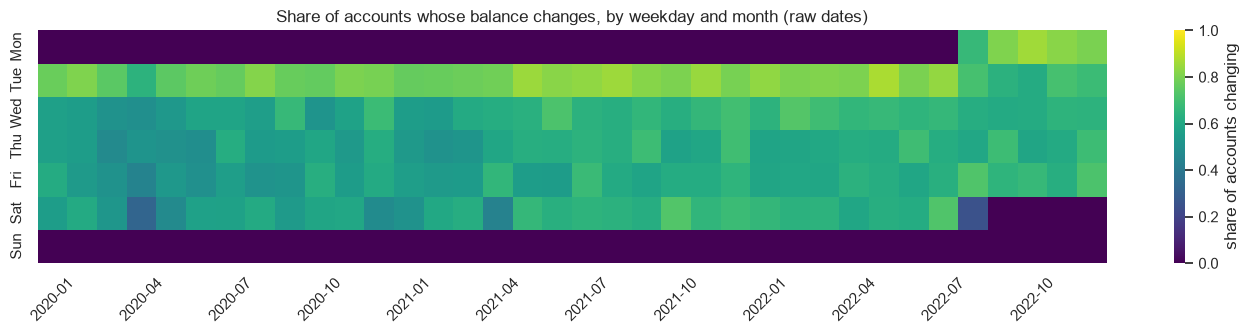

In [4]:
def change_share(wide):
    """Share of (observed) accounts whose balance changed vs the previous day, per date."""
    x = wide.to_numpy()
    d = np.diff(x, axis=1)
    valid = ~np.isnan(d)
    return pd.Series(((d != 0) & valid).sum(0) / np.maximum(valid.sum(0), 1), index=wide.columns[1:])


share_raw = change_share(raw)
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_month_weekday = (share_raw.groupby([share_raw.index.to_period("M"), share_raw.index.dayofweek]).mean()
                    .unstack().rename(columns=dict(enumerate(weekday_names))))
save_result(by_month_weekday.rename(index=str), "03_change_share_month_weekday_raw",
            "Raw labels: share of accounts whose balance changes, by month x weekday (shows the Aug-2022 switch)")
save_result(share_raw.rename("share_changing"), "03_change_share_daily_raw",
            "Raw labels: share of accounts whose balance changes, per date")

fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(by_month_weekday.T, cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "share of accounts changing"})
ax.set_xticks(np.arange(0, len(by_month_weekday), 3) + 0.5,
              [str(p) for p in by_month_weekday.index[::3]], rotation=45)
ax.set(title="Share of accounts whose balance changes, by weekday and month (raw dates)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

**Finding — the date convention changes in August 2022.**

| Period (raw labels) | Balances change on | Flat on |
|---|---|---|
| until 2022-08-06 | Tuesday – Saturday | Sunday, Monday |
| from 2022-08-07 | Monday – Friday | Saturday, Sunday |

Until August 2022, the balance labelled with day *D* is the closing balance of day *D − 1* (Monday's transactions
appear on Tuesday's label, Friday's on Saturday's, and nothing happens on Sunday's and Monday's labels).
From August 2022 the label is the closing balance of the same day. The forecast period (the 30 days after the data
ends) follows the **new** convention, so if we leave the history as it is, models would learn a weekly pattern that is
shifted by one day for ~85% of the sample.

Two further checks support the *D − 1* reading and identify the exact switch.

In [5]:
# (a) Holidays: if label D = close of D-1, activity should drop on labels that FOLLOW a holiday (old convention).
pt_holidays = holidays.Portugal(years=range(dates.min().year, dates.max().year + 2))
old_conv = share_raw[share_raw.index < "2022-08-01"]
tue_sat = old_conv[(old_conv.index.dayofweek >= 1) & (old_conv.index.dayofweek <= 5)]
prev_is_holiday = np.array([(d - pd.Timedelta(days=1)) in pt_holidays for d in tue_sat.index])
same_is_holiday = np.array([d in pt_holidays for d in tue_sat.index])
holiday_check = pd.Series({
    "label after a holiday (old convention)": tue_sat[prev_is_holiday].mean(),
    "label on a holiday (old convention)": tue_sat[same_is_holiday].mean(),
    "other Tue-Sat labels": tue_sat[~prev_is_holiday & ~same_is_holiday].mean(),
}).round(3).rename("share of accounts changing")
save_result(holiday_check, "03_holiday_check_old_convention",
            "Old date convention: activity on labels after/on holidays (supports label D = close of D-1)")
display(holiday_check.to_frame())

# (b) The switch itself
window = raw.loc[:, "2022-08-02":"2022-08-09"]
display(window.head(8).round(2))
display(change_share(raw.loc[:, "2022-08-01":"2022-08-10"]).round(2).to_frame("share changing")
        .assign(weekday=lambda t: t.index.day_name()))

,share of accounts changing
label after a holiday (old convention),0.450
label on a holiday (old convention),0.662
other Tue-Sat labels,0.640


date,2022-08-02,2022-08-03,2022-08-04,2022-08-05,2022-08-06,2022-08-07,2022-08-08,2022-08-09
ACCOUNT_ID,,,,,,,,
1,7783.69,7661.65,8770.96,17541.92,8770.96,8770.96,7489.69,7489.69
2,4012.35,3815.50,3815.50,7631.00,3815.50,3815.50,3815.50,3815.50
3,522.57,448.45,81.31,340.68,139.27,139.27,128.46,35.14
4,37840.52,37840.52,37840.52,75681.04,37840.52,37840.52,37253.94,37090.45
5,12081.10,12837.17,12065.78,24129.04,12063.26,12063.26,12063.26,12032.51
6,989.72,989.72,835.78,1671.56,835.78,835.78,805.73,805.73
7,320.91,320.91,299.61,735.84,459.12,459.12,418.25,405.34
8,552.73,147.98,106.32,155.93,49.61,49.61,-34.45,-34.45


,share changing,weekday
date,,
2022-08-02,0.89,Tuesday
2022-08-03,0.65,Wednesday
2022-08-04,0.61,Thursday
2022-08-05,1.00,Friday
2022-08-06,1.00,Saturday
2022-08-07,0.00,Sunday
2022-08-08,0.86,Monday
2022-08-09,0.68,Tuesday
2022-08-10,0.64,Wednesday


- Under the old convention, activity drops on the label *after* a holiday, not on the holiday itself — consistent
  with "label D = close of D − 1".
- Around the switch, the label **2022-08-05 is corrupted**: it changes for 100% of accounts, and its value is the
  **sum of two consecutive closing balances** (e.g. account 1: 17 541.92 = 8 770.96 + 8 770.96). It is the Thursday
  close (old label 2022-08-05) added to the Friday close (old label 2022-08-06) during the migration. The Thursday
  close can be recovered exactly as `label(08-05) − label(08-06)`.
- The label 2022-08-07 (a Sunday, new convention) is identical to label 2022-08-06 for every account, as expected
  (no activity between Friday's close and Sunday).

**Decision — realign the calendar.**
1. Repair the corrupted label: `label(2022-08-05) ← label(2022-08-05) − label(2022-08-06)`.
2. Shift every label up to 2022-08-06 back by one day (label *D* → date *D − 1*).
3. The resulting gap on Saturday 2022-08-06 is filled with Sunday's balance (no transactions happen on weekends
   under the new convention).

After this, every value is the **closing balance of its own date**, consistently over the whole sample.

,value
dates after realignment,2020-01-01 -> 2022-12-31 (1096 days)
repaired Thursday 2022-08-04: median |change| vs Wednesday,19.86
typical weekday median |change| (2022),14.81


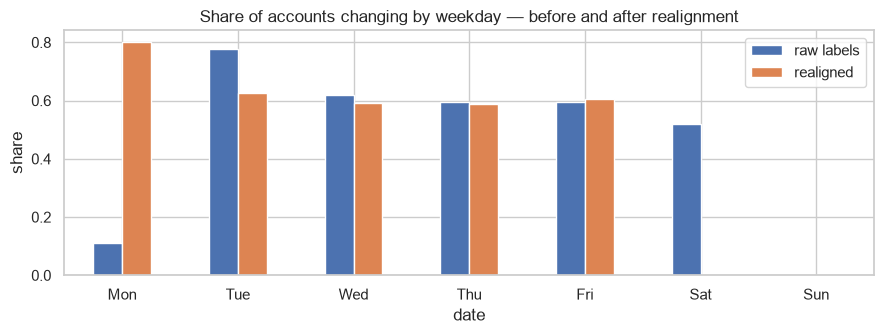

In [6]:
SWITCH_FIRST_NEW_LABEL = pd.Timestamp("2022-08-07")   # first label recorded with the same-day convention
CORRUPTED_LABEL = pd.Timestamp("2022-08-05")          # sum of two closing balances
NEXT_LABEL = pd.Timestamp("2022-08-06")


def realign_calendar(wide):
    """Return a frame where every column is the closing balance of that same date."""
    old = wide.loc[:, wide.columns < SWITCH_FIRST_NEW_LABEL].copy()
    new = wide.loc[:, wide.columns >= SWITCH_FIRST_NEW_LABEL]
    if CORRUPTED_LABEL in old.columns and NEXT_LABEL in old.columns:
        old[CORRUPTED_LABEL] = old[CORRUPTED_LABEL] - old[NEXT_LABEL]
    old.columns = old.columns - pd.Timedelta(days=1)
    out = pd.concat([old, new], axis=1)
    full = pd.date_range(out.columns.min(), out.columns.max(), freq="D")
    gaps = full.difference(out.columns)
    out = out.reindex(columns=full)
    for g in gaps:                       # weekend day left empty by the shift -> next day's balance
        out[g] = out[g + pd.Timedelta(days=1)]
    out.columns.name = "date"
    return out


bal = realign_calendar(raw)
share = change_share(bal)

repaired = bal[pd.Timestamp("2022-08-04")]
check = pd.Series({
    "dates after realignment": f"{bal.columns.min().date()} -> {bal.columns.max().date()} ({bal.shape[1]} days)",
    "repaired Thursday 2022-08-04: median |change| vs Wednesday": round(float((repaired - bal[pd.Timestamp("2022-08-03")]).abs().median()), 2),
    "typical weekday median |change| (2022)": round(float(bal.loc[:, "2022-01-01":"2022-12-31"].diff(axis=1).abs().median().median()), 2),
})
display(check.to_frame("value"))

compare = pd.DataFrame({
    "raw labels": share_raw.groupby(share_raw.index.dayofweek).mean(),
    "realigned": share.groupby(share.index.dayofweek).mean(),
}).rename(index=dict(enumerate(weekday_names)))
save_result(check.astype(str).rename("value"), "03_realignment_check", "Checks of the realigned calendar and repaired day")
save_result(compare, "03_weekday_activity_before_after", "Share of accounts changing by weekday: raw vs realigned")
compare.plot.bar(figsize=(9, 3.5), rot=0, title="Share of accounts changing by weekday — before and after realignment")
plt.ylabel("share"); plt.tight_layout(); plt.show()

After realignment, balances change Monday–Friday and are flat on weekends throughout the whole sample, and the
repaired Thursday looks like any other weekday. **All the analysis below uses the realigned data (`bal`).**

## 4. Descriptive statistics
Accounts are very heterogeneous in scale, so we describe them **per account** and look at the cross-section of those
statistics. Daily *changes* are analysed separately from *levels*.

,count,mean,std,min,5%,25%,50%,75%,95%,max
mean,500.0,11531.30,105595.29,-1499.81,-108.07,183.41,723.40,3694.56,26466.24,2247008.97
median,500.0,8413.73,55953.67,-1732.27,-254.34,33.87,481.87,2577.30,21051.10,1056714.11
std,500.0,8877.70,111233.61,68.56,182.86,395.32,888.48,2630.32,16897.21,2472436.78
min,500.0,455.35,22903.58,-140167.78,-1563.48,-355.64,-147.14,57.08,5955.39,324740.99
max,500.0,37379.12,368436.94,381.13,919.27,2106.38,5430.85,17425.66,85631.52,8119331.47
skewness,500.0,1.96,3.55,-31.30,-0.57,0.63,1.34,2.62,7.79,21.20
excess_kurtosis,500.0,21.10,72.39,-1.82,-1.10,0.11,2.31,9.85,87.47,1015.08
share_negative,500.0,0.22,0.27,0.00,0.00,0.00,0.07,0.40,0.76,0.98
share_days_changed,500.0,0.46,0.11,0.28,0.30,0.37,0.46,0.54,0.63,0.70
cv,500.0,3.00,8.74,0.05,0.29,0.64,1.08,2.22,9.45,123.58


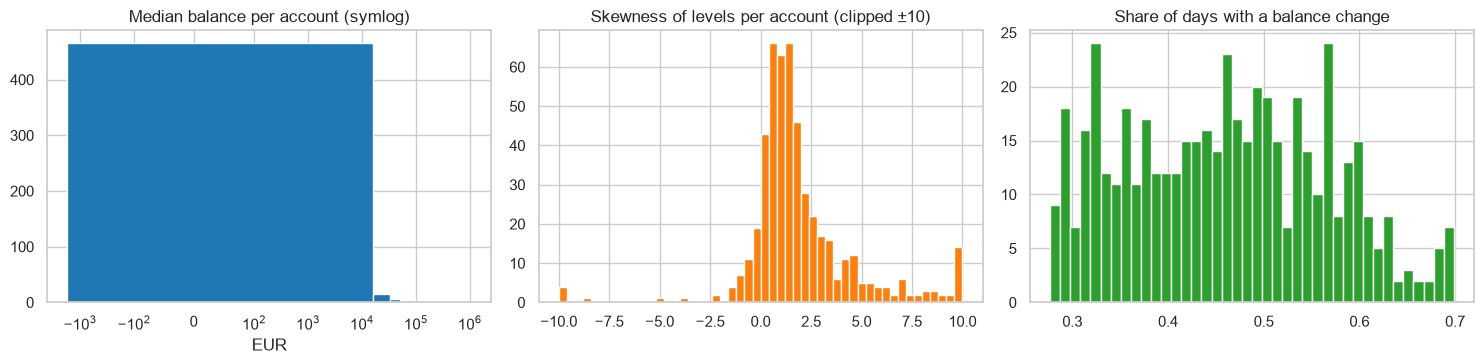

In [7]:
B = bal.to_numpy()
dB = np.diff(B, axis=1)

per_account = pd.DataFrame({
    "mean": np.nanmean(B, 1),
    "median": np.nanmedian(B, 1),
    "std": np.nanstd(B, 1),
    "min": np.nanmin(B, 1),
    "max": np.nanmax(B, 1),
    "skewness": stats.skew(B, axis=1, nan_policy="omit"),
    "excess_kurtosis": stats.kurtosis(B, axis=1, nan_policy="omit"),
    "share_negative": np.nanmean(np.where(np.isnan(B), np.nan, B < 0), 1),
    "share_days_changed": np.sum((dB != 0) & ~np.isnan(dB), 1) / np.sum(~np.isnan(dB), 1),
}, index=bal.index)
per_account["cv"] = per_account["std"] / per_account["mean"].abs()

display(per_account.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(per_account["median"], bins=60, color="tab:blue")
axes[0].set_xscale("symlog", linthresh=100); axes[0].set(title="Median balance per account (symlog)", xlabel="EUR")
axes[1].hist(per_account["skewness"].clip(-10, 10), bins=50, color="tab:orange")
axes[1].set(title="Skewness of levels per account (clipped ±10)")
axes[2].hist(per_account["share_days_changed"], bins=40, color="tab:green")
axes[2].set(title="Share of days with a balance change")
plt.tight_layout(); plt.show()

**Normality of daily changes.** Models such as ARIMA assume (approximately) Gaussian innovations. We test daily
changes (on business days, where they can be non-zero) with Jarque–Bera.

In [8]:
test_ids = sample_accounts(bal.index, MAX_TEST_ACCOUNTS)
business = (bal.columns[1:].dayofweek < 5)
jb_p = []
for acc in test_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())
    x = x[business[-len(x):]] if len(x) else x
    jb_p.append(stats.jarque_bera(x).pvalue if len(x) > 30 else np.nan)
jb_p = pd.Series(jb_p, index=test_ids)
per_account["jarque_bera_p_changes"] = jb_p
save_result(per_account, "04_per_account_statistics",
            "Per account: mean, median, std, min, max, skewness, kurtosis, share negative, activity, CV, JB p-value")
save_result(per_account.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T, "04_per_account_statistics_summary",
            "Distribution across accounts of the per-account statistics")
print(f"Jarque-Bera rejects normality of daily changes (p < 0.05) for {100 * (jb_p < 0.05).mean():.1f}% "
      f"of {len(test_ids)} accounts")

Jarque-Bera rejects normality of daily changes (p < 0.05) for 100.0% of 500 accounts


**Findings.**
- Scales span several orders of magnitude (median balances from a few euros to hundreds of thousands), so any
  cross-account model must work on a **scaled** target (e.g. divided by each account's typical level).
- Levels are strongly skewed with heavy tails, and daily changes are **not Gaussian** for practically every account:
  most days have a change of exactly zero and a few days carry large jumps (salaries, transfers).
- Many accounts are inactive on most days — balances are *piecewise constant*, which favours simple level-based
  forecasts (naive, recent mean/median) as strong baselines.

## 5. Zeros, negative and near-zero balances — the MAPE problem
MAPE divides each error by the actual value: it is **undefined for a zero balance** and explodes when the balance is
close to zero. The organisers did not specify how these cases are handled, so we quantify them here.

In [9]:
obs = B[~np.isnan(B)]
last = B[:, -HORIZON:]
sign_type = np.select(
    [per_account["min"] > 0, per_account["max"] < 0],
    ["always positive", "always negative"], default="changes sign")
near_zero = pd.Series({
    "exact zeros": int((obs == 0).sum()),
    "% of balances negative": round(100 * (obs < 0).mean(), 2),
    f"% of balances with |x| < {NEAR_ZERO:.0f} EUR": round(100 * (np.abs(obs) < NEAR_ZERO).mean(), 2),
    "% of balances with |x| < 10 EUR": round(100 * (np.abs(obs) < 10).mean(), 2),
    f"% of last-{HORIZON}-day balances with |x| < {NEAR_ZERO:.0f} EUR": round(100 * np.nanmean(np.abs(last) < NEAR_ZERO), 2),
})
display(near_zero.to_frame("value"))
display(pd.Series(sign_type, index=bal.index).value_counts().to_frame("accounts"))
save_result(near_zero.rename("value"), "05_near_zero_summary", "Zeros, negatives and near-zero balances (MAPE risk)")
save_result(pd.Series(sign_type, index=bal.index, name="sign_type"), "05_sign_type_per_account",
            "Per account: always positive / always negative / changes sign")

# Illustration: the same absolute error (EUR 50) produces wildly different percentage errors
illus = pd.DataFrame({"actual": [5000, 500, 100, 20, 5, 1]})
illus["forecast"] = illus["actual"] + 50
illus["APE (%)"] = (100 * (illus["actual"] - illus["forecast"]).abs() / illus["actual"].abs()).round(1)
illus

,value
exact zeros,6.00
% of balances negative,22.12
% of balances with |x| < 100 EUR,17.02
% of balances with |x| < 10 EUR,2.43
% of last-30-day balances with |x| < 100 EUR,14.68


,accounts
changes sign,358
always positive,142


,actual,forecast,APE (%)
0,5000,5050,1.0
1,500,550,10.0
2,100,150,50.0
3,20,70,250.0
4,5,55,1000.0
5,1,51,5000.0


**Findings.**
- Exact zeros are rare, but a large share of balances is **close to zero**, and most accounts **cross zero** at some
  point (overdrafts / credit lines). Negative balances are legitimate and must be allowed in the forecasts.
- A €50 error is 1% on a €5 000 balance but 1 000% on a €5 balance: the official MAPE will be **dominated by a
  handful of near-zero points**.

**Decision — evaluation protocol.** Since the treatment is unspecified, every model will be reported with three
numbers, defined once in Section 16:
1. **MAPE (official)** — the formula of the brief, pooled over all accounts and days; exact zeros are excluded
   because the formula is undefined there. *This is the primary metric.*
2. **Median per-account MAPE** — robust view of the typical account.
3. **MAPE on |actual| ≥ €100** — the error on "meaningful" balances.

This also has a modelling consequence for Sprint 2: under MAPE, forecasts should be biased towards *smaller absolute
values* when uncertain (MAPE penalises over-forecasting a small balance much more than under-forecasting a big one).

## 6. Extreme values
Extremes are looked for in **daily changes** and in levels. Since most days have no change at all, the robust
z-score (distance from the median in MAD units) is computed on the **non-zero changes** of each account.
We distinguish **spikes** (a jump that is reversed within the next days — e.g. money in and straight out) from
**level shifts** (a permanent new level).

,value
non-zero daily changes,248673.0
% of non-zero changes with robust z > 5,14.2
% of non-zero changes with robust z > 10 (extreme),7.9
extreme moves reversed within 3 days (spikes),438.0
% of extreme moves that are spikes,2.2
accounts with at least one extreme move,497.0


,max |balance|
ACCOUNT_ID,
192,8119331.0
323,1152403.0
54,541167.0
371,487162.0
445,305199.0


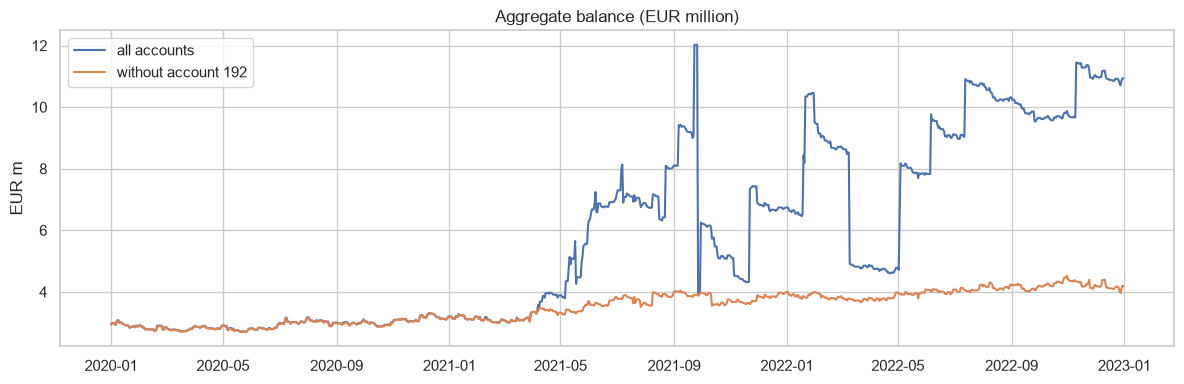

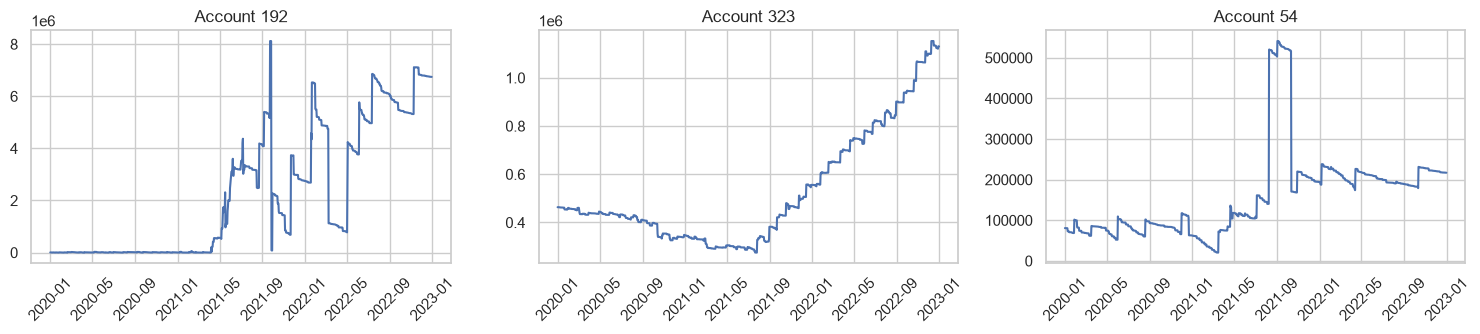

In [10]:
nonzero = np.where((dB != 0) & ~np.isnan(dB), dB, np.nan)
med = np.nanmedian(nonzero, 1, keepdims=True)
mad = 1.4826 * np.nanmedian(np.abs(nonzero - med), 1, keepdims=True)
z = np.abs(nonzero - med) / np.where(mad > 0, mad, np.nan)
big = z > 10

# spike = extreme move followed (within 3 days, to cover weekends) by a move that cancels >= 90% of it
spike = np.zeros_like(big)
for lag in (1, 2, 3):
    nxt = np.full_like(dB, np.nan); nxt[:, :-lag] = dB[:, lag:]
    spike |= big & (np.abs(dB + nxt) <= 0.1 * np.abs(dB))

n_nonzero = int(np.sum(~np.isnan(nonzero)))
extremes = pd.Series({
    "non-zero daily changes": n_nonzero,
    "% of non-zero changes with robust z > 5": round(100 * np.nansum(z > 5) / n_nonzero, 1),
    "% of non-zero changes with robust z > 10 (extreme)": round(100 * big.sum() / n_nonzero, 1),
    "extreme moves reversed within 3 days (spikes)": int(spike.sum()),
    "% of extreme moves that are spikes": round(100 * spike.sum() / max(big.sum(), 1), 1),
    "accounts with at least one extreme move": int(big.any(1).sum()),
})
display(extremes.to_frame("value"))

# Largest accounts and the effect of a single account on the aggregate
top = per_account["max"].abs().sort_values(ascending=False).head(5)
display(top.round(0).to_frame("max |balance|"))
save_result(extremes.rename("value"), "06_extremes_summary", "Extreme daily moves (robust z on non-zero changes) and spikes")
save_result(pd.DataFrame({"extreme_moves": big.sum(1), "spikes": spike.sum(1)}, index=bal.index),
            "06_extremes_per_account", "Per account: number of extreme moves and reversed spikes")
save_result(top.rename("max_abs_balance"), "06_top_accounts", "Accounts with the largest absolute balances")
total = bal.sum(0)
total_wo_top = bal.drop(index=top.index[:1]).sum(0)
fig, ax = plt.subplots()
ax.plot(total.index, total / 1e6, label="all accounts")
ax.plot(total_wo_top.index, total_wo_top / 1e6, label=f"without account {top.index[0]}")
ax.set(title="Aggregate balance (EUR million)", ylabel="EUR m"); ax.legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for ax, acc in zip(axes, top.index[:3]):
    ax.plot(bal.columns, bal.loc[acc]); ax.set_title(f"Account {acc}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Findings.**
- Daily changes are extremely **heavy-tailed**: a sizeable share of non-zero moves lies more than 10 robust standard
  deviations from the typical move. Only a small fraction are reversed spikes: most are **permanent level shifts**
  (salary arrivals, large transfers, account re-purposing). These are real behaviour, not data errors, so they are
  **not removed** — removing them would make the history look calmer than reality.
- A single account can dominate the aggregate (one account grows from thousands to millions of euros). Any analysis of
  the total balance must be read with that in mind, and the aggregate is **not** a good proxy for the typical account.
  Per-account MAPE is scale-free, so these accounts do not dominate the metric — but they do dominate any
  unscaled pooled model, which is another reason to scale per account.

# Part B — Temporal structure
## 7. Calendar effects
We relate balance *changes* to the day of the week, the day of the month, the month and Portuguese public holidays.
Changes are scaled by each account's median absolute balance so that accounts are comparable.

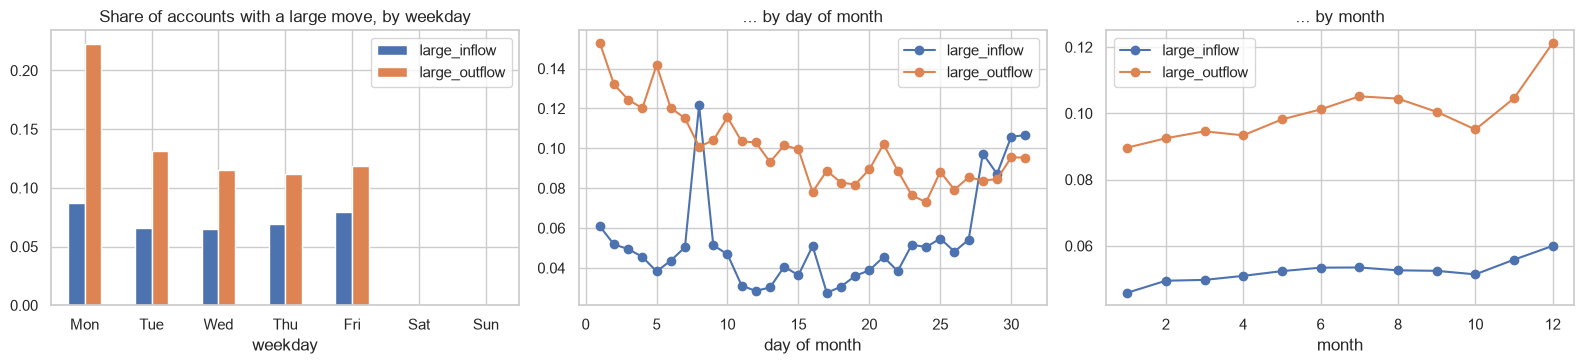

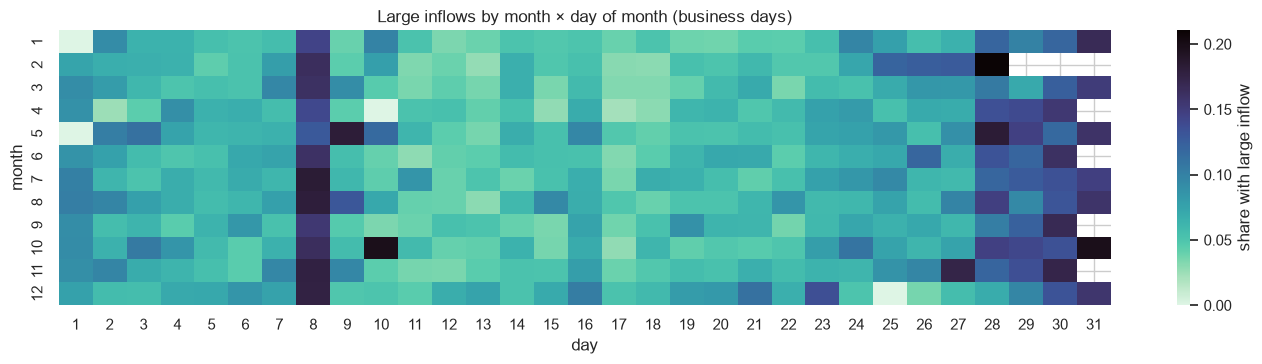

In [11]:
typical = np.nanmedian(np.abs(B), 1, keepdims=True)
rel = dB / np.where(typical > 0, typical, np.nan)          # relative daily change
rel = np.clip(rel, -5, 5)                                  # limit the influence of extreme relative moves
cd = bal.columns[1:]
inflow = (rel > 0.2)                                       # "large inflow": +20% of the typical balance in a day
outflow = (rel < -0.2)

cal = pd.DataFrame({
    "weekday": cd.dayofweek, "day": cd.day, "month": cd.month,
    "share_changing": share.values,
    "large_inflow": np.nanmean(np.where(np.isnan(rel), np.nan, inflow), 0),
    "large_outflow": np.nanmean(np.where(np.isnan(rel), np.nan, outflow), 0),
    "mean_rel_change": np.nanmean(rel, 0),
}, index=cd)
save_result(cal, "07_calendar_daily", "Per date: weekday/day/month, share changing, share with large inflow/outflow, mean relative change")
for g in ["weekday", "day", "month"]:
    save_result(cal.groupby(g)[["share_changing", "large_inflow", "large_outflow", "mean_rel_change"]].mean(),
                f"07_calendar_by_{g}", f"Calendar effects aggregated by {g}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
cal.groupby("weekday")[["large_inflow", "large_outflow"]].mean().rename(index=dict(enumerate(weekday_names))).plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Share of accounts with a large move, by weekday")
cal.groupby("day")[["large_inflow", "large_outflow"]].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="... by day of month", xlabel="day of month")
cal.groupby("month")[["large_inflow", "large_outflow"]].mean().plot(ax=axes[2], marker="o")
axes[2].set(title="... by month", xlabel="month")
plt.tight_layout(); plt.show()

heat = cal[cal.weekday < 5].pivot_table(index="month", columns="day", values="large_inflow", aggfunc="mean")
fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(heat, cmap="mako_r", ax=ax, cbar_kws={"label": "share with large inflow"})
ax.set(title="Large inflows by month × day of month (business days)"); plt.tight_layout(); plt.show()

**Are the differences statistically significant?** Kruskal–Wallis test (non-parametric ANOVA, appropriate given the
non-normal changes) of the relative change across groups, on business days.

In [12]:
pts = pd.DataFrame({"rel": rel.ravel(),
                    "weekday": np.tile(cd.dayofweek, rel.shape[0]),
                    "day": np.tile(cd.day, rel.shape[0]),
                    "month": np.tile(cd.month, rel.shape[0])}).dropna()
pts = pts[pts.weekday < 5]
if len(pts) > 2_000_000:
    pts = pts.sample(2_000_000, random_state=RANDOM_STATE)
kw = {}
for g in ["weekday", "day", "month"]:
    groups = [v.to_numpy() for _, v in pts.groupby(g)["rel"]]
    h, p = stats.kruskal(*groups)
    kw[g] = {"H statistic": round(h, 1), "p-value": p}
kw = pd.DataFrame(kw).T
display(kw)

# Holidays (business days only)
bd = cal[cal.weekday < 5]
is_hol = np.array([d in pt_holidays for d in bd.index])
holiday_effect = pd.DataFrame({"holiday": bd[is_hol][["share_changing", "large_inflow"]].mean(),
                               "normal business day": bd[~is_hol][["share_changing", "large_inflow"]].mean()}).round(3)
display(holiday_effect)
save_result(kw, "07_kruskal_wallis", "Kruskal-Wallis tests of relative daily change by weekday, day of month, month")
save_result(holiday_effect, "07_holiday_effect", "Activity on Portuguese public holidays vs normal business days")

,H statistic,p-value
weekday,6555.6,0.000000e+00
day,3649.2,0.000000e+00
month,442.6,5.333444e-88


,holiday,normal business day
share_changing,0.508,0.647
large_inflow,0.059,0.074


**Findings.**
- **Weekly cycle:** after realignment, transactions happen on business days only; Saturdays and Sundays are flat.
  Monday is the most active day (it absorbs the weekend's card payments and transfers), followed by Friday.
- **Monthly cycle:** large inflows peak at the **end of the month** (days 28–31, salaries) and on **day 8**
  (consistent with the payment date of Social Security pensions); large outflows peak in the **first days of the
  month** (direct debits, rents, loan instalments). Day-of-month is highly significant.
- **Holidays** have clearly less activity than normal business days.
- **Month of year** is statistically significant but weak in magnitude (slightly more inflows in December,
  fewest in January).

**Implication for modelling:** the useful seasonalities are **weekly (7)** and **monthly (~30 days: end-of-month
salaries, day-8 pensions, early-month debits)**, plus a business-day/holiday calendar. The forecast window
(January) starts right after the Christmas period and contains a turn of the month.

## 8. Example series
A random sample of accounts, to see the typical shapes.

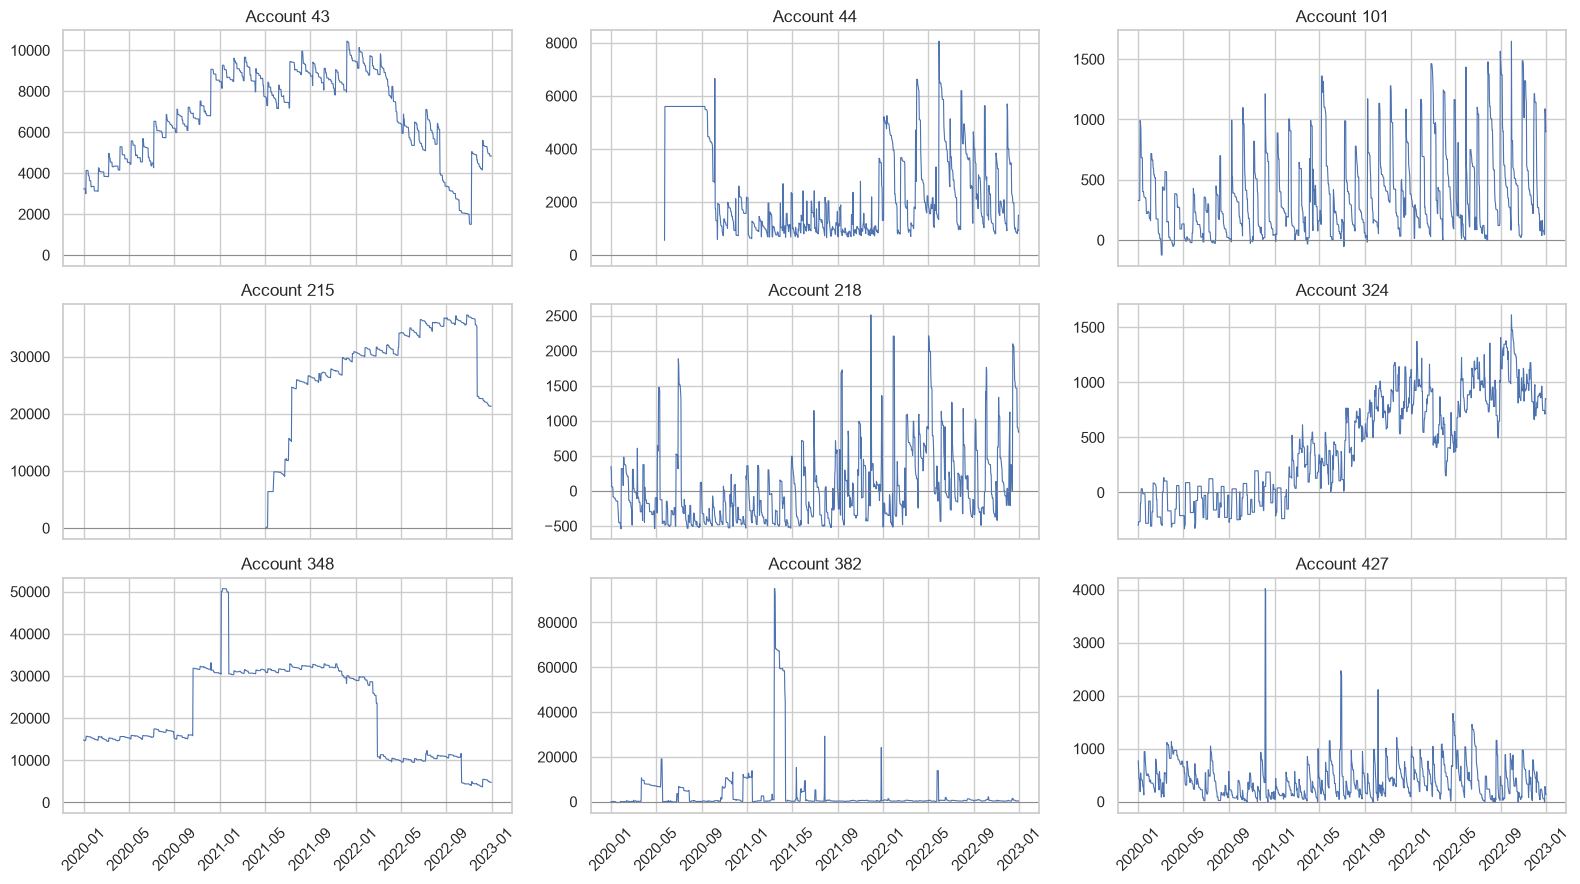

In [13]:
examples = sample_accounts(bal.index, 9)
fig, axes = plt.subplots(3, 3, figsize=(16, 9), sharex=True)
for ax, acc in zip(axes.ravel(), examples):
    ax.plot(bal.columns, bal.loc[acc], lw=0.8)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"Account {acc}")
for ax in axes[-1]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Typical shapes: step-like series (salary in, gradual spending out — a "saw-tooth" with a monthly period), long
flat periods, occasional permanent level shifts, and accounts that oscillate around zero.

## 9. Decomposition (MSTL)
Multi-seasonal STL with weekly (7) and monthly (30) periods. Because a few large accounts dominate the total, we
decompose the **cross-sectional median balance** (the "typical account") and a few individual accounts.

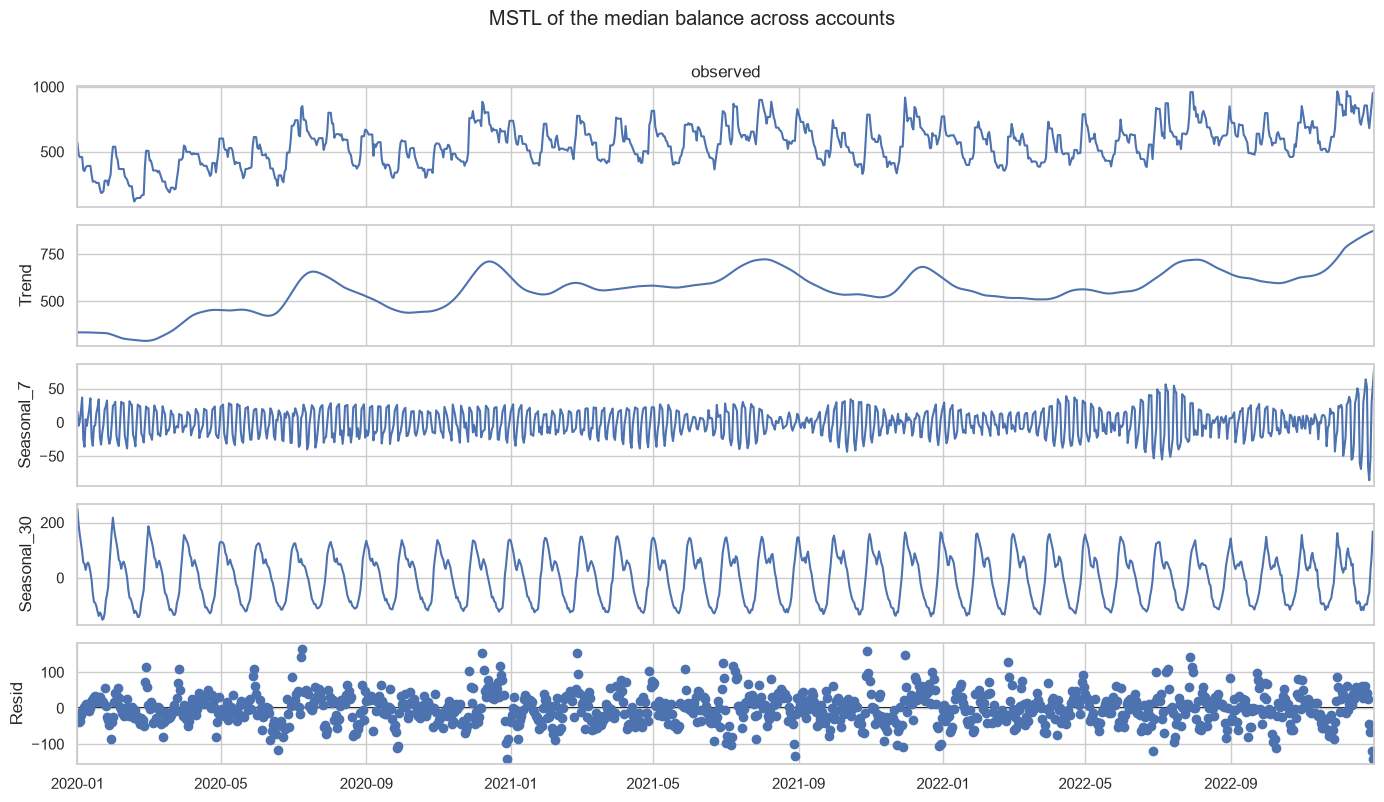

,median account (series),per-account (median of strengths)
trend,0.874,0.824
weekly (7),0.201,0.099
monthly (30),0.813,0.386


In [14]:
typical_series = bal.median(axis=0)
mstl = MSTL(typical_series, periods=(7, 30)).fit()
fig = mstl.plot(); fig.set_size_inches(14, 8); fig.suptitle("MSTL of the median balance across accounts", y=1.0)
plt.tight_layout(); plt.show()

# Strength of each component (Hyndman & Athanasopoulos): 1 - Var(resid) / Var(component + resid)
def strength(component, resid):
    return max(0.0, 1 - np.var(resid) / np.var(component + resid))


def component_strengths(series):
    res = MSTL(series, periods=(7, 30)).fit()
    return {"trend": strength(res.trend, res.resid),
            "weekly (7)": strength(res.seasonal["seasonal_7"], res.resid),
            "monthly (30)": strength(res.seasonal["seasonal_30"], res.resid)}


strengths = {}
for acc in sample_accounts(bal.index, min(200, MAX_TEST_ACCOUNTS)):
    s = bal.loc[acc].dropna()
    if len(s) >= 120:
        strengths[acc] = component_strengths(s)
strengths = pd.DataFrame(strengths).T
strength_summary = pd.concat({"median account (series)": pd.Series(component_strengths(typical_series)),
                              "per-account (median of strengths)": strengths.median()}, axis=1).round(3)
display(strength_summary)
save_result(strength_summary, "09_mstl_strength_summary", "MSTL component strengths: median-account series and per-account median")
save_result(strengths, "09_mstl_strength_per_account", "Per account (sample): strength of trend, weekly and monthly components")
save_result(pd.DataFrame({"observed": typical_series, "trend": mstl.trend, "seasonal_7": mstl.seasonal["seasonal_7"],
                          "seasonal_30": mstl.seasonal["seasonal_30"], "resid": mstl.resid}),
            "09_mstl_median_account", "MSTL decomposition of the cross-sectional median balance")

**Findings.** The trend component dominates; the monthly component is clearly stronger than the weekly one (the
weekly pattern is mostly "flat on weekends", which matters for daily forecasts but explains little variance).
Per account the seasonal strengths vary a lot — some accounts have a clear monthly salary cycle, others none —
which argues for **per-account (or per-segment) seasonal models**.

## 10. Stationarity
ADF (H0: unit root) and KPSS (H0: stationary) are complementary, so we run both, on levels and on first differences.

In [15]:
def stationarity_tests(x):
    out = {}
    for name, series in (("level", x), ("diff", np.diff(x))):
        try:
            out[f"adf_p_{name}"] = adfuller(series, autolag="AIC")[1]
            out[f"kpss_p_{name}"] = kpss(series, regression="c", nlags="auto")[1]
        except Exception:
            out[f"adf_p_{name}"] = out[f"kpss_p_{name}"] = np.nan
    return out


st = pd.DataFrame({acc: stationarity_tests(bal.loc[acc].dropna().to_numpy()) for acc in test_ids}).T


def classify(adf_p, kpss_p, alpha=0.05):
    if adf_p < alpha and kpss_p >= alpha:
        return "stationary (both agree)"
    if adf_p >= alpha and kpss_p < alpha:
        return "unit root (both agree)"
    if adf_p < alpha and kpss_p < alpha:
        return "conflicting: difference-stationary / level shifts"
    return "inconclusive"


st["levels"] = [classify(a, k) for a, k in zip(st.adf_p_level, st.kpss_p_level)]
st["first differences"] = [classify(a, k) for a, k in zip(st.adf_p_diff, st.kpss_p_diff)]
st_summary = pd.concat([st["levels"].value_counts(normalize=True), st["first differences"].value_counts(normalize=True)],
                       axis=1).fillna(0).mul(100).round(1).rename_axis("% of accounts")
display(st_summary)
save_result(st, "10_stationarity_per_account", "Per account: ADF and KPSS p-values (levels, differences) and classification")
save_result(st_summary, "10_stationarity_summary", "% of accounts per stationarity class, levels vs first differences")

,proportion,proportion
% of accounts,,
conflicting: difference-stationary / level shifts,47.8,1.0
unit root (both agree),29.4,0.0
stationary (both agree),21.4,99.0
inconclusive,1.4,0.0


**Findings.** In levels the two tests disagree for a large share of accounts — the signature of series with
**level shifts** (stationary between jumps, but not around a single mean). After **one difference**, practically
all accounts are stationary according to both tests. ⇒ For ARIMA-type models, **d = 1** is the natural choice;
models in levels must allow the mean to move (e.g. local level / exponential smoothing).

## 11. Autocorrelation
ACF/PACF of the median-account series, and the distribution of the ACF of daily changes across accounts.

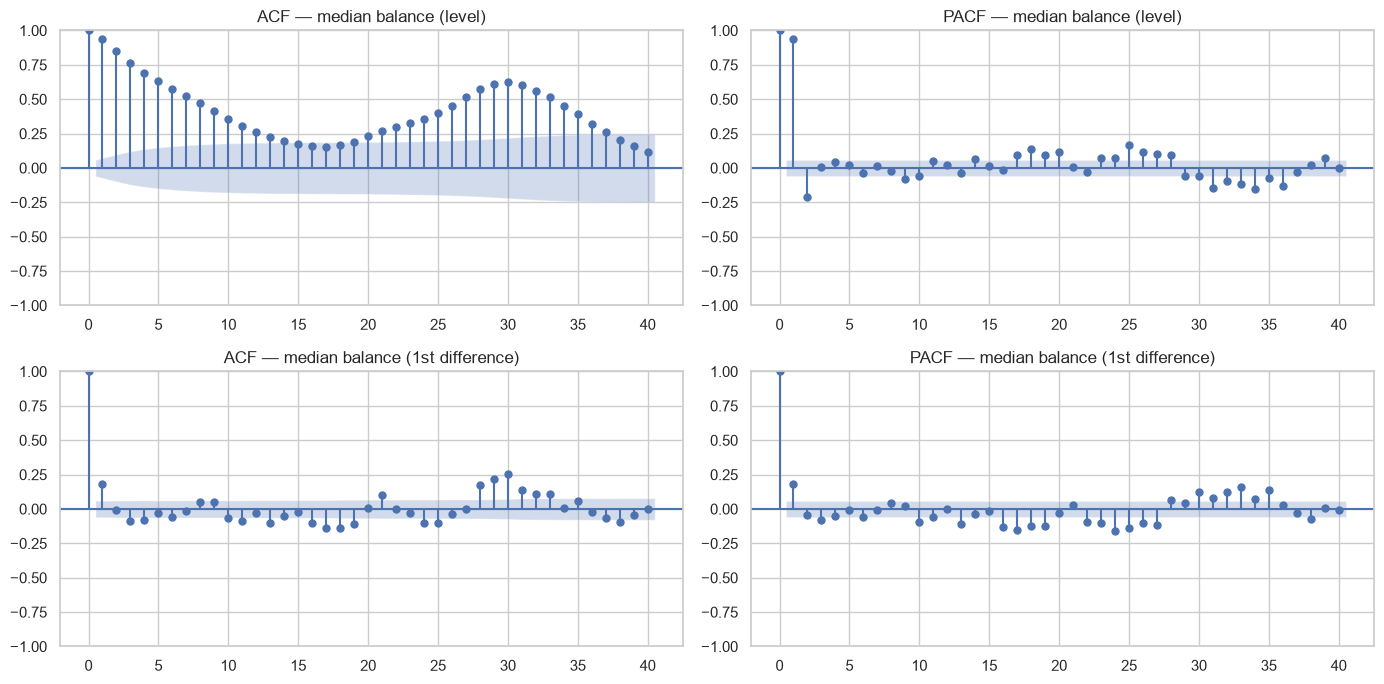

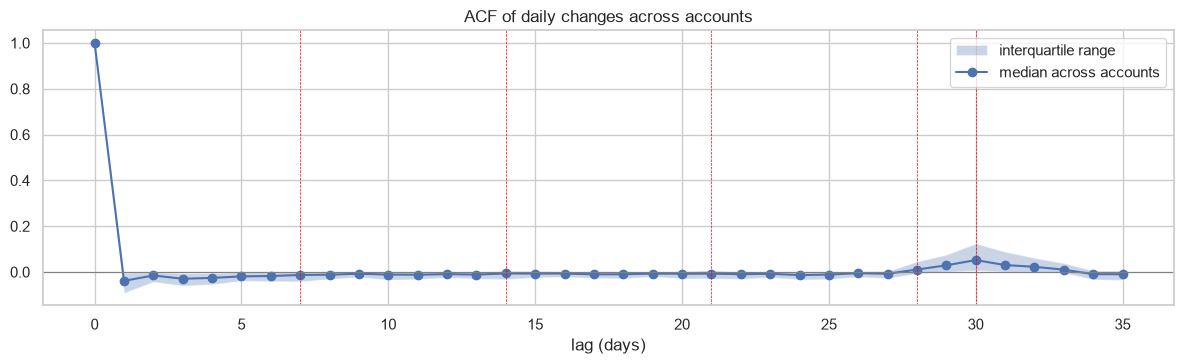

Ljung-Box rejects 'no autocorrelation' in daily changes: lag 7 -> 66.0% of accounts, lag 30 -> 83.4%


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(typical_series, lags=40, ax=axes[0, 0], title="ACF — median balance (level)")
plot_pacf(typical_series, lags=40, ax=axes[0, 1], title="PACF — median balance (level)", method="ywm")
plot_acf(typical_series.diff().dropna(), lags=40, ax=axes[1, 0], title="ACF — median balance (1st difference)")
plot_pacf(typical_series.diff().dropna(), lags=40, ax=axes[1, 1], title="PACF — median balance (1st difference)", method="ywm")
plt.tight_layout(); plt.show()

NLAGS = 35
acfs, lb7, lb30, acf_ids = [], [], [], []
for acc in test_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())
    if np.std(x) == 0:
        continue
    acf_ids.append(acc)
    acfs.append(acf(x, nlags=NLAGS, fft=True))
    lb = acorr_ljungbox(x, lags=[7, 30])
    lb7.append(lb["lb_pvalue"].iloc[0]); lb30.append(lb["lb_pvalue"].iloc[1])
acfs = np.array(acfs)
save_result(pd.DataFrame(acfs, index=pd.Index(acf_ids, name="ACCOUNT_ID"), columns=[f"lag_{l}" for l in range(NLAGS + 1)]),
            "11_acf_changes_per_account", "Per account: ACF of daily changes, lags 0-35")
save_result(pd.DataFrame({"median": np.median(acfs, 0), "p25": np.percentile(acfs, 25, 0), "p75": np.percentile(acfs, 75, 0)},
                         index=pd.Index(range(NLAGS + 1), name="lag")),
            "11_acf_changes_summary", "Median and IQR across accounts of the ACF of daily changes")
save_result(pd.DataFrame({"ljung_box_p_lag7": lb7, "ljung_box_p_lag30": lb30}, index=pd.Index(acf_ids, name="ACCOUNT_ID")),
            "11_ljung_box_per_account", "Per account: Ljung-Box p-values on daily changes (lags 7 and 30)")
save_result(pd.DataFrame({"acf": acf(typical_series, nlags=40), "pacf": pacf(typical_series, nlags=40),
                          "acf_diff": acf(typical_series.diff().dropna(), nlags=40),
                          "pacf_diff": pacf(typical_series.diff().dropna(), nlags=40)},
                         index=pd.Index(range(41), name="lag")),
            "11_acf_pacf_median_account", "ACF/PACF of the median-account series, levels and first differences")
fig, ax = plt.subplots(figsize=(12, 3.8))
lags = np.arange(NLAGS + 1)
ax.fill_between(lags, np.percentile(acfs, 25, 0), np.percentile(acfs, 75, 0), alpha=0.3, label="interquartile range")
ax.plot(lags, np.median(acfs, 0), marker="o", label="median across accounts")
ax.axhline(0, color="grey", lw=0.8)
for l in (7, 14, 21, 28, 30):
    ax.axvline(l, color="red", lw=0.5, ls="--")
ax.set(title="ACF of daily changes across accounts", xlabel="lag (days)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Ljung-Box rejects 'no autocorrelation' in daily changes: lag 7 -> {100 * np.mean(np.array(lb7) < 0.05):.1f}% "
      f"of accounts, lag 30 -> {100 * np.mean(np.array(lb30) < 0.05):.1f}%")

**Findings.** The level is highly persistent (slowly decaying ACF; PACF with a large spike at lag 1 and a small one
at lag 2 → close to a random walk). For the typical account, daily changes have a slightly negative short-lag
autocorrelation (partial reversals) and a **positive peak around lag 28–31 (monthly cycle)**; there is no clear
weekly peak in the changes themselves (the weekly effect is "no movement at weekends", not a repeated amount).
Ljung–Box confirms there is structure left after differencing for most accounts.
⇒ Candidate models in Sprint 2: **ARIMA(p,1,q)** with short AR/MA terms, with the monthly cycle captured by a
30-day seasonal component or calendar regressors, and the weekly effect by a business-day calendar.

## 12. Volatility
Does the size of daily changes cluster in time (calm and agitated periods)? Engle's ARCH-LM test on daily changes.

ARCH-LM rejects homoscedasticity for 36.8% of accounts


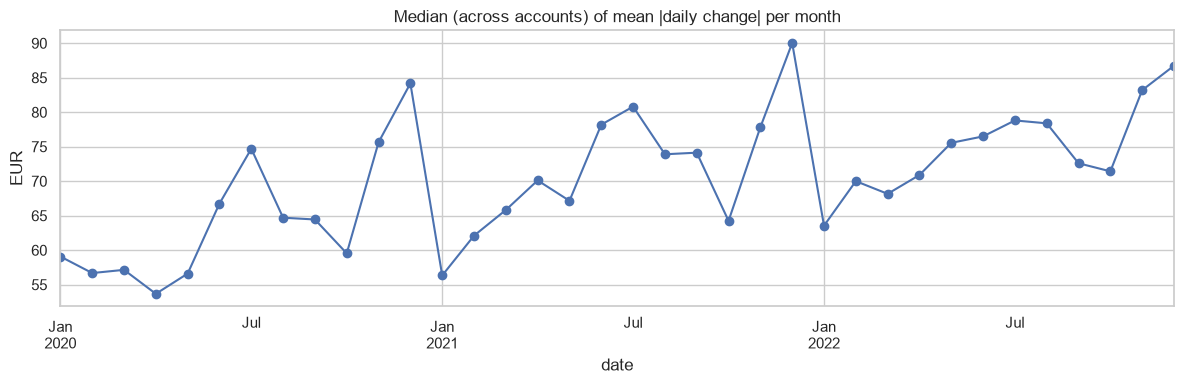

In [17]:
arch_p = []
for acc in test_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())
    arch_p.append(het_arch(x, nlags=7)[1] if np.std(x) > 0 else np.nan)
arch_p = pd.Series(arch_p, index=test_ids)
print(f"ARCH-LM rejects homoscedasticity for {100 * (arch_p < 0.05).mean():.1f}% of accounts")

monthly_vol = pd.DataFrame(np.abs(dB), columns=cd).T.groupby(cd.to_period("M")).mean().median(axis=1)
save_result(arch_p.rename("arch_lm_p"), "12_arch_per_account", "Per account: ARCH-LM p-value on daily changes (7 lags)")
save_result(monthly_vol.rename(index=str).rename("median_mean_abs_change"), "12_monthly_volatility",
            "Per month: median across accounts of the mean absolute daily change")
monthly_vol.plot(title="Median (across accounts) of mean |daily change| per month", marker="o")
plt.ylabel("EUR"); plt.tight_layout(); plt.show()

**Finding.** About a third of the accounts show significant volatility clustering. For point forecasts this matters
mainly for **prediction intervals** and for weighting recent data more than old data; it does not justify
GARCH-type models for this task.

## 13. Structural changes over the sample
Comparison of the three years: level, activity and the share of accounts with negative balances.

In [18]:
yearly = pd.DataFrame({
    "median balance (median account)": bal.median(0).groupby(bal.columns.year).mean(),
    "share of balances negative (%)": (bal < 0).where(bal.notna()).mean(0).groupby(bal.columns.year).mean() * 100,
    "share of accounts changing per business day": share[share.index.dayofweek < 5].groupby(share.index[share.index.dayofweek < 5].year).mean(),
    "active accounts": bal.notna().sum(0).groupby(bal.columns.year).max(),
}).round(3)
save_result(yearly, "13_yearly_summary", "Per year: typical balance, share negative, activity, active accounts")
yearly

,median balance (median account),share of balances negative (%),share of accounts changing per business day,active accounts
date,,,,
2020,472.617,28.302231,0.595,495
2021,596.225,22.329808,0.654,500
2022,613.656,15.931507,0.678,500


**Findings.** Balances of the typical account grow from 2020 to 2022, the share of negative balances falls
markedly, and activity increases every year (2020 was the first COVID year). The most important structural break is not economic but the **August 2022 change in the date
convention** found in Section 3, already corrected. For the forecast, the **most recent months are the most
representative**.

# Part C — Relationships between accounts
## 14. Cross-account correlation
Correlating **levels** of trending series produces spurious correlation (two unrelated accounts that both grow look
correlated). We therefore correlate **daily changes**, and show levels only for contrast.

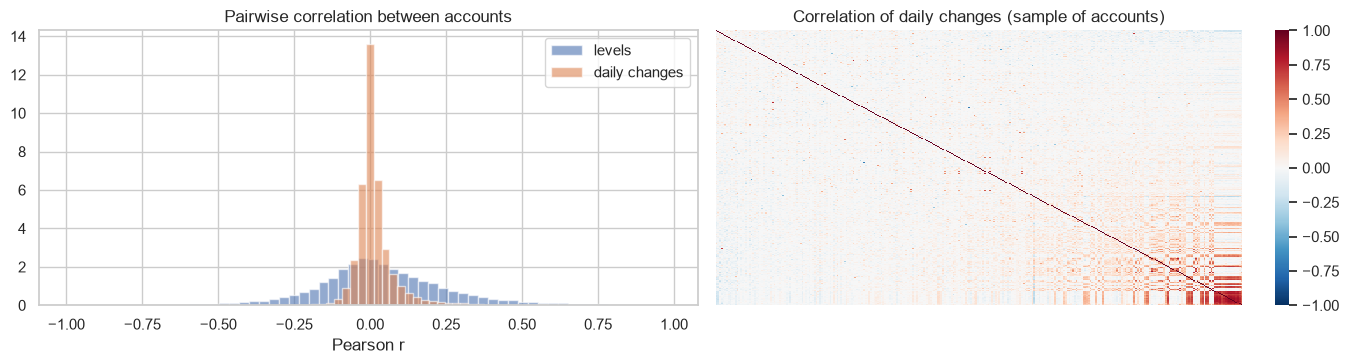

,levels,daily changes
count,44850.000,44850.000
mean,0.038,0.019
std,0.223,0.088
min,-0.991,-0.688
5%,-0.304,-0.060
50%,0.021,0.002
95%,0.427,0.148
max,0.979,0.867


In [19]:
corr_ids = sample_accounts(bal.index, MAX_CORR_ACCOUNTS)
changes = bal.loc[corr_ids].T.diff().iloc[1:]
changes = changes.loc[changes.index.dayofweek < 5]           # business days only
corr_changes = changes.corr(min_periods=60).to_numpy()
corr_levels = bal.loc[corr_ids].T.corr(min_periods=60).to_numpy()
iu = np.triu_indices_from(corr_changes, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(corr_levels[iu], bins=60, alpha=0.6, label="levels", density=True)
axes[0].hist(corr_changes[iu], bins=60, alpha=0.6, label="daily changes", density=True)
axes[0].set(title="Pairwise correlation between accounts", xlabel="Pearson r"); axes[0].legend()
order_idx = np.argsort(np.nan_to_num(corr_changes).mean(0))
sns.heatmap(corr_changes[np.ix_(order_idx, order_idx)], cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1],
            xticklabels=False, yticklabels=False)
axes[1].set(title="Correlation of daily changes (sample of accounts)")
plt.tight_layout(); plt.show()
corr_summary = pd.DataFrame({
    "levels": pd.Series(corr_levels[iu]).describe(percentiles=[0.05, 0.5, 0.95]),
    "daily changes": pd.Series(corr_changes[iu]).describe(percentiles=[0.05, 0.5, 0.95]),
}).round(3)
display(corr_summary)
pairs = pd.DataFrame({"account_a": corr_ids[iu[0]], "account_b": corr_ids[iu[1]],
                      "corr_changes": corr_changes[iu], "corr_levels": corr_levels[iu]})
top_pairs = pairs.reindex(pairs.corr_changes.abs().sort_values(ascending=False).index).head(50)
save_result(corr_summary, "14_correlation_summary", "Distribution of pairwise correlations: levels vs daily changes (sample)")
save_result(top_pairs, "14_top_correlated_pairs", "50 account pairs with the strongest correlation of daily changes", index=False)

**Findings.** Correlations between accounts are **weak**: the median pairwise correlation of daily changes is close
to zero, with only a few strongly correlated pairs (possibly accounts of the same client or linked accounts).
Correlation in levels is spread in both directions — mostly spurious, driven by trends.
⇒ A full multivariate model (e.g. VAR across accounts) is **not justified**. Accounts share a *common calendar*
(salaries, weekends, holidays), not common shocks, so information is best shared through **global models with
calendar features**, while dynamics stay per account.

## 15. Segmentation of accounts
Simple, interpretable rules based on the features computed above (last 12 months, i.e. the most representative
period), to be used in Sprint 2 to choose or tune models per segment.

,accounts,activity,share_near_zero,share_negative,cv,median_balance,% accounts
segment,,,,,,,
dormant,1,0.049,0.984,0.775,7.748,-1.690,0.2
near-zero / overdraft,195,0.495,0.400,0.332,1.769,49.440,39.0
stable positive,138,0.456,0.000,0.000,0.253,6847.485,27.6
volatile positive,166,0.534,0.047,0.005,0.764,809.410,33.2


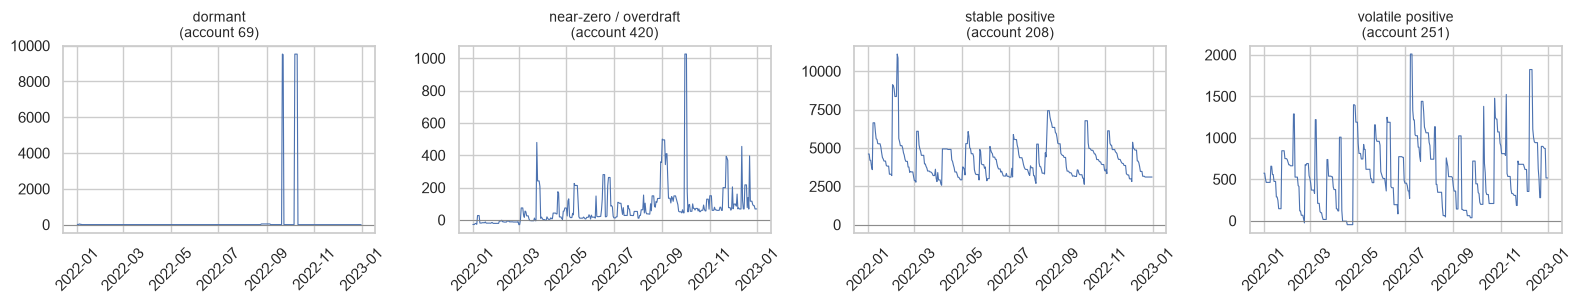

In [20]:
recent = bal.loc[:, bal.columns > bal.columns.max() - pd.Timedelta(days=365)]
R = recent.to_numpy(); dR = np.diff(R, axis=1)
feat = pd.DataFrame({
    "activity": np.sum((dR != 0) & ~np.isnan(dR), 1) / np.sum(~np.isnan(dR), 1),
    "share_near_zero": np.nanmean(np.where(np.isnan(R), np.nan, np.abs(R) < NEAR_ZERO), 1),
    "share_negative": np.nanmean(np.where(np.isnan(R), np.nan, R < 0), 1),
    "cv": np.nanstd(R, 1) / np.abs(np.nanmean(R, 1)),
    "median_balance": np.nanmedian(R, 1),
}, index=bal.index)


def segment(r):
    if r.activity < 0.05:
        return "dormant"
    if r.share_near_zero > 0.25 or r.share_negative > 0.25:
        return "near-zero / overdraft"
    if r.cv < 0.5:
        return "stable positive"
    return "volatile positive"


feat["segment"] = feat.apply(segment, axis=1)
seg_summary = feat.groupby("segment").agg(
    accounts=("activity", "size"), activity=("activity", "median"), share_near_zero=("share_near_zero", "median"),
    share_negative=("share_negative", "median"), cv=("cv", "median"), median_balance=("median_balance", "median"))
seg_summary["% accounts"] = (100 * seg_summary.accounts / len(feat)).round(1)
display(seg_summary.round(3))
save_result(feat, "15_segments_per_account", "Per account: last-12-month features and segment")
save_result(seg_summary, "15_segment_summary", "Per segment: number of accounts and median features")

fig, axes = plt.subplots(1, len(seg_summary), figsize=(16, 3.2))
for ax, seg in zip(np.atleast_1d(axes), seg_summary.index):
    ids = feat.index[feat.segment == seg]
    acc = ids[rng.integers(len(ids))]
    ax.plot(recent.columns, recent.loc[acc], lw=0.8); ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"{seg}\n(account {acc})", fontsize=10); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Findings.** The **near-zero / overdraft** segment is where MAPE will be decided: those accounts produce the huge
percentage errors. Dormant accounts are trivially forecast by their last value. Stable and volatile positive
accounts are where seasonal/ARIMA models should add value over the naive forecast.

# Part D — Decisions
## 16. Data-preparation decisions

| # | Issue (evidence) | Decision |
|---|---|---|
| 1 | Date convention changes in Aug 2022: before, label *D* = close of *D − 1* (§3) | **Realign**: shift pre-switch labels back one day; fill the single resulting weekend gap |
| 2 | Label 2022-08-05 is the sum of two closing balances (§3) | **Repair** exactly: `label(08-05) − label(08-06)` |
| 3 | Missing values are all leading — accounts opened later (§2) | **No imputation**; each account starts at its first observation |
| 4 | Negative balances are frequent and legitimate (§5) | **Keep**; forecasts must allow negative values; no log transform of levels |
| 5 | Zero / near-zero balances make MAPE explode (§5) | Report 3 metrics (official MAPE as primary); handle near-zero accounts explicitly in Sprint 2 |
| 6 | Extreme moves are mostly permanent level shifts (§6) | **Keep** (real behaviour); revisit as anomalies in Sprint 3 |
| 7 | Scales differ by orders of magnitude (§4) | **Scale per account** for any cross-account model |
| 8 | Weekly + monthly seasonality, holidays (§7, §9) | Use calendar features: weekday, day of month, end-of-month, PT holidays |
| 9 | Level shifts, unit roots in levels (§10–11) | Models on differences (d = 1) or local-level models; weight recent data |
| 10 | Weak cross-account correlation (§14) | No VAR across accounts; global model + per-account dynamics |

The prepared dataset is `bal`: the realigned, repaired accounts × days matrix with leading NaNs preserved.

In [21]:
prepared = bal.copy()
save_result(prepared.rename(columns=lambda c: c.strftime("%Y-%m-%d")), "16_prepared_balances",
            "PREPARED DATASET (wide, same layout as the raw file): realigned calendar, repaired 2022-08-05, leading NaN kept")
display(pd.Series({
    "accounts": prepared.shape[0],
    "days": prepared.shape[1],
    "first date": prepared.columns.min().date(),
    "last date": prepared.columns.max().date(),
    "missing (leading only)": int(prepared.isna().sum().sum()),
}).to_frame("prepared dataset"))

,prepared dataset
accounts,500
days,1096
first date,2020-01-01
last date,2022-12-31
missing (leading only),5853


## 17. Validation scheme and baselines
**Rolling-origin backtesting.** Each fold trains on everything up to an origin and forecasts the next 30 days,
mimicking the real task. Folds:
- the last four 30-day windows of 2022 (most recent behaviour, new date convention);
- January 2022 — the **same season** as the real forecast window (right after Christmas, salary at month end).

**Metrics** (see §5): official MAPE (pooled, exact zeros excluded) — primary; median per-account MAPE;
MAPE on |actual| ≥ €100.

In [22]:
def mape_official(actual, forecast):
    """MAPE as in the brief, pooled over all points; undefined points (actual = 0 or missing) are excluded."""
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (a != 0)
    return 100 * np.mean(np.abs((a[ok] - f[ok]) / a[ok]))


def mape_per_account(actual, forecast, min_abs=0.0):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (np.abs(a) > min_abs)
    ape = np.where(ok, np.abs((a - f) / np.where(ok, a, 1)), np.nan)
    return 100 * np.nanmean(ape, axis=1)


def evaluate(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (np.abs(a) >= NEAR_ZERO)
    return {"MAPE (official)": mape_official(a, f),
            "median per-account MAPE": np.nanmedian(mape_per_account(a, f)),
            f"MAPE |actual|>={NEAR_ZERO:.0f}": 100 * np.mean(np.abs((a[ok] - f[ok]) / a[ok]))}


def baselines(train):
    """Simple forecasts from the training matrix (accounts x days) for HORIZON days."""
    T = train.to_numpy()
    last_value = T[:, -1:]
    last_week = T[:, -7:]
    reps = int(np.ceil(HORIZON / 7))
    return {
        "naive (last value)": np.repeat(last_value, HORIZON, axis=1),
        "seasonal naive (last week)": np.tile(last_week, reps)[:, :HORIZON],
        "mean of last 30 days": np.repeat(np.nanmean(T[:, -30:], 1, keepdims=True), HORIZON, axis=1),
        "median of last 30 days": np.repeat(np.nanmedian(T[:, -30:], 1, keepdims=True), HORIZON, axis=1),
    }


last_day = prepared.columns.max()
origins = [last_day - pd.Timedelta(days=HORIZON * k) for k in (4, 3, 2, 1)]       # end of training data
origins = [pd.Timestamp("2021-12-31")] + origins
results = []
for origin in origins:
    train = prepared.loc[:, :origin]
    test = prepared.loc[:, origin + pd.Timedelta(days=1): origin + pd.Timedelta(days=HORIZON)]
    for name, fc in baselines(train).items():
        results.append({"fold (test start)": (origin + pd.Timedelta(days=1)).date(), "model": name,
                        **evaluate(test.to_numpy(), fc)})
results = pd.DataFrame(results)
display(results.pivot(index="model", columns="fold (test start)", values="MAPE (official)").round(1))
summary = results.groupby("model")[[c for c in results.columns if "MAPE" in c]].mean().sort_values(f"MAPE |actual|>={NEAR_ZERO:.0f}")
save_result(results, "17_baselines_by_fold", "Baseline forecasts: three MAPE metrics per fold and model", index=False)
save_result(summary, "17_baselines_summary", "Baseline forecasts: metrics averaged over folds (reference for Sprint 2)")
summary.round(1)

fold (test start),2022-01-01,2022-09-03,2022-10-03,2022-11-02,2022-12-02
model,,,,,
mean of last 30 days,812.4,519.3,723.2,3804.2,9023.9
median of last 30 days,593.5,314.2,334.3,3408.7,10512.6
naive (last value),768.3,652.4,794.9,3916.4,381.8
seasonal naive (last week),640.8,715.8,716.6,4368.7,299.0


,MAPE (official),median per-account MAPE,MAPE |actual|>=100
model,,,
median of last 30 days,3032.6,66.5,71.5
mean of last 30 days,2976.6,72.5,78.4
naive (last value),1302.7,68.8,88.7
seasonal naive (last week),1348.2,78.8,98.3


**Findings.**
- The official (pooled) MAPE is **one order of magnitude larger** than the other two metrics and very unstable across
  folds — it is driven by a few near-zero actuals, exactly as anticipated in §5.
- The ranking depends on the metric: on the official MAPE the naive last value is best on average, while on the
  robust metrics the **median of the last 30 days** is best — balances fluctuate around a level within the month,
  so a robust average helps on normal balances but hurts when the actual balance is near zero.
- The seasonal naive is never the best — repeating last week's exact path propagates noise.
- These numbers are the **reference to beat in Sprint 2**, and the disagreement between metrics confirms that the
  near-zero accounts need a dedicated strategy.

## 18. Conclusions and inputs for Sprint 2
1. **Data corrections:** the history mixes two date conventions and contains one corrupted day; both are fixed by
   realigning the calendar and repairing the doubled balance. Without this fix, any weekly pattern would be wrong.
2. **Missing values** only reflect accounts opened during the period — no imputation needed.
3. **The metric is the main difficulty:** frequent near-zero and sign-changing balances make MAPE explode. Sprint 2
   must treat near-zero accounts explicitly and consider MAPE-aware forecasts (biased towards smaller |values|).
4. **Seasonality:** weekly (business days vs weekends) and monthly (turn-of-month inflows), plus holidays.
5. **Dynamics:** levels behave like random walks with level shifts; first differences are stationary (d = 1), with
   short-memory autocorrelation and volatility clustering.
6. **Cross-section:** accounts are nearly independent and very heterogeneous in scale → per-account models, or a
   global model on scaled data with calendar features; segment-specific strategies.
7. **Validation:** rolling-origin backtesting with 30-day horizons including January 2022; baselines to beat are in
   §17.

## 19. Saved results
One table per account combining every per-account result, and the index of all CSV files written to `data/sprint1/`.

In [23]:
account_features = (per_account
                    .join(first_obs.rename("first_observation_raw_label"))
                    .join(pd.Series(sign_type, index=bal.index, name="sign_type"))
                    .join(pd.DataFrame({"extreme_moves": big.sum(1), "spikes": spike.sum(1)}, index=bal.index))
                    .join(st[["adf_p_level", "kpss_p_level", "levels", "first differences"]]
                          .rename(columns={"levels": "stationarity_levels", "first differences": "stationarity_diff"}))
                    .join(pd.DataFrame({"ljung_box_p_lag7": lb7, "ljung_box_p_lag30": lb30}, index=acf_ids))
                    .join(arch_p.rename("arch_lm_p"))
                    .join(strengths.add_prefix("mstl_strength_"))
                    .join(feat.add_suffix("_last12m")))
save_result(account_features, "00_account_features", "ONE ROW PER ACCOUNT: all per-account statistics, tests and segment")

index = pd.DataFrame(saved_files)
if SAVE_RESULTS:
    index.to_csv(RESULTS_DIR / "00_index.csv", index=False)
    print(f"{len(index)} result files written to {RESULTS_DIR}")
index

41 result files written to C:\Users\manue\Desktop\mestrado\2026-2027\EQC\case-study-iii-millenium-bcp\data\sprint1


,file,description,rows,columns
0,01_structure.csv,"Dataset structure: size, date range, duplicates",9,1
1,02_missing_summary.csv,Missing values: totals by type (leading/traili...,7,1
2,02_first_observation.csv,Per account: first observed (raw) date and num...,500,2
3,03_change_share_month_weekday_raw.csv,Raw labels: share of accounts whose balance ch...,36,7
4,03_change_share_daily_raw.csv,Raw labels: share of accounts whose balance ch...,1094,1
5,03_holiday_check_old_convention.csv,Old date convention: activity on labels after/...,3,1
6,03_realignment_check.csv,Checks of the realigned calendar and repaired day,3,1
7,03_weekday_activity_before_after.csv,Share of accounts changing by weekday: raw vs ...,7,2
8,04_per_account_statistics.csv,"Per account: mean, median, std, min, max, skew...",500,11
9,04_per_account_statistics_summary.csv,Distribution across accounts of the per-accoun...,11,10
